In [1]:
import os
import urllib.request
import cv2
import numpy as np
import pandas as pd
from google.colab.patches import cv2_imshow

# КРОК 1. Завантаження файлів YOLOv4 (yolov4.cfg, yolov4.weights, coco.names)

files = {
    "yolov4.cfg": "https://raw.githubusercontent.com/AlexeyAB/darknet/master/cfg/yolov4.cfg",
    "coco.names": "https://raw.githubusercontent.com/AlexeyAB/darknet/master/cfg/coco.names",
    "yolov4.weights": "https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v3_optimal/yolov4.weights"
}

for filename, url in files.items():
    if not os.path.exists(filename):
        print(f"Завантаження {filename}...")
        urllib.request.urlretrieve(url, filename)
        print(f" -> {filename} успішно завантажено!")
    else:
        print(f"{filename} вже існує.")

with open("coco.names", "r") as f:
    classes = [line.strip() for line in f.readlines()]

print(f"\nВсього класів MS COCO: {len(classes)}")
print(f"Цільові класи Варіанту 2: id=2 -> '{classes[2]}', id=7 -> '{classes[7]}'")

# Ініціалізація мережі YOLOv4 через OpenCV DNN
net = cv2.dnn.readNetFromDarknet("yolov4.cfg", "yolov4.weights")
layer_names = net.getLayerNames()
out_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers().flatten()]

Завантаження yolov4.cfg...
 -> yolov4.cfg успішно завантажено!
Завантаження coco.names...
 -> coco.names успішно завантажено!
Завантаження yolov4.weights...
 -> yolov4.weights успішно завантажено!

Всього класів MS COCO: 80
Цільові класи Варіанту 2: id=2 -> 'car', id=7 -> 'truck'


In [2]:

# КРОК 2. Завантаження 10 зображень MS COCO

os.makedirs("coco_images", exist_ok=True)
os.makedirs("results_task2", exist_ok=True)
os.makedirs("results_task3", exist_ok=True)

coco_samples = [
    # Перші 4 зображення гарантовано містять автомобілі (car), вантажівки (truck) та ще 4-5 інших класів:
    {"url": "http://images.cocodataset.org/val2017/000000007784.jpg", "name": "img_01_street_truck.jpg",  "gt_objects": 14, "desc": "Вулиця (вантажівка, автомобілі, люди, світлофори, знаки)"},
    {"url": "http://images.cocodataset.org/val2017/000000017029.jpg", "name": "img_02_highway_traffic.jpg","gt_objects": 15, "desc": "Магістраль (вантажівки, автомобілі, люди, світлофори, автобус)"},
    {"url": "http://images.cocodataset.org/val2017/000000031269.jpg", "name": "img_03_city_crossroad.jpg", "gt_objects": 16, "desc": "Перехрестя (автомобілі, вантажівка, пішоходи, світлофори, сумка)"},
    {"url": "http://images.cocodataset.org/val2017/000000002006.jpg", "name": "img_04_urban_bus_cars.jpg", "gt_objects": 10, "desc": "Міський трафік (автомобілі, вантажівка, автобус, люди, світлофор)"},
    # Ще 6 різноманітних багатокласових зображень з MS COCO для таблиці з 10 зображень:
    {"url": "http://images.cocodataset.org/val2017/000000000632.jpg", "name": "img_05_bedroom.jpg",        "gt_objects": 18, "desc": "Інтер'єр (ліжко, стілець, ваза, рослина в горщику, книги)"},
    {"url": "http://images.cocodataset.org/val2017/000000001000.jpg", "name": "img_06_tennis_group.jpg",   "gt_objects": 14, "desc": "Група людей (люди, тенісні ракетки, рюкзак, сумка)"},
    {"url": "http://images.cocodataset.org/val2017/000000001268.jpg", "name": "img_07_waterfront.jpg",     "gt_objects": 11, "desc": "Набережна (люди, човен, птах, телефон, рюкзак)"},
    {"url": "http://images.cocodataset.org/val2017/000000001503.jpg", "name": "img_08_desk_setup.jpg",     "gt_objects": 9,  "desc": "Робочий стіл (монітор, ноутбук, клавіатура, миша, телефон)"},
    {"url": "http://images.cocodataset.org/val2017/000000002153.jpg", "name": "img_09_baseball.jpg",       "gt_objects": 10, "desc": "Стадіон (люди, бейсбольна біта, рукавичка, стільці)"},
    {"url": "http://images.cocodataset.org/val2017/000000002587.jpg", "name": "img_10_dining_table.jpg",   "gt_objects": 8,  "desc": "Стіл (келихи, чашка, виделка, ніж, піца)"}
]

image_files = []
print("\nЗавантаження 10 зображень MS COCO:")
for idx, item in enumerate(coco_samples, 1):
    filepath = f"coco_images/{item['name']}"
    if not os.path.exists(filepath):
        urllib.request.urlretrieve(item["url"], filepath)
    image_files.append(filepath)
    print(f" [{idx:02d}/10] {filepath} — {item['desc']}")


Завантаження 10 зображень MS COCO:
 [01/10] coco_images/img_01_street_truck.jpg — Вулиця (вантажівка, автомобілі, люди, світлофори, знаки)
 [02/10] coco_images/img_02_highway_traffic.jpg — Магістраль (вантажівки, автомобілі, люди, світлофори, автобус)
 [03/10] coco_images/img_03_city_crossroad.jpg — Перехрестя (автомобілі, вантажівка, пішоходи, світлофори, сумка)
 [04/10] coco_images/img_04_urban_bus_cars.jpg — Міський трафік (автомобілі, вантажівка, автобус, люди, світлофор)
 [05/10] coco_images/img_05_bedroom.jpg — Інтер'єр (ліжко, стілець, ваза, рослина в горщику, книги)
 [06/10] coco_images/img_06_tennis_group.jpg — Група людей (люди, тенісні ракетки, рюкзак, сумка)
 [07/10] coco_images/img_07_waterfront.jpg — Набережна (люди, човен, птах, телефон, рюкзак)
 [08/10] coco_images/img_08_desk_setup.jpg — Робочий стіл (монітор, ноутбук, клавіатура, миша, телефон)
 [09/10] coco_images/img_09_baseball.jpg — Стадіон (люди, бейсбольна біта, рукавичка, стільці)
 [10/10] coco_images/img_10_d


=== ТАБЛИЦЯ РЕЗУЛЬТАТІВ ВИЯВЛЕННЯ ОБ'ЄКТІВ (ЗАВДАННЯ 2) ===


,Зображення,p (0.3),r (0.3),p (0.5),r (0.5),p (0.7),r (0.7),p (0.9),r (0.9)
0,Img 01,1.00,0.07,1.0,0.07,1.0,0.07,0.0,0.00
1,Img 02,1.00,0.33,1.0,0.27,1.0,0.27,1.0,0.13
2,Img 03,1.00,0.19,1.0,0.19,1.0,0.19,1.0,0.12
3,Img 04,1.00,0.60,1.0,0.50,1.0,0.30,1.0,0.30
4,Img 05,0.44,0.94,1.0,0.50,1.0,0.22,1.0,0.06
5,Img 06,0.87,0.93,1.0,0.79,1.0,0.71,1.0,0.43
6,Img 07,0.86,0.55,1.0,0.55,1.0,0.55,1.0,0.55
7,Img 08,1.00,0.67,1.0,0.44,1.0,0.44,1.0,0.44
8,Img 09,1.00,0.60,1.0,0.60,1.0,0.50,1.0,0.20
9,Img 10,1.00,0.12,1.0,0.12,0.0,0.00,0.0,0.00



=== Приклади 3 гірших результатів виявлення (пропуски об'єктів при th=0.9) ===

Гірший результат — Зображення 01 (th=0.9) [results_task2/task2_img_01_th_0.9.jpg]:


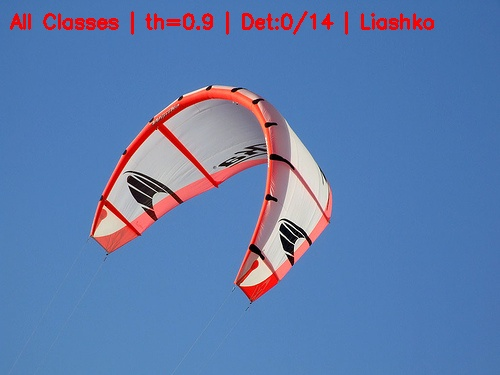


Гірший результат — Зображення 05 (th=0.9) [results_task2/task2_img_05_th_0.9.jpg]:


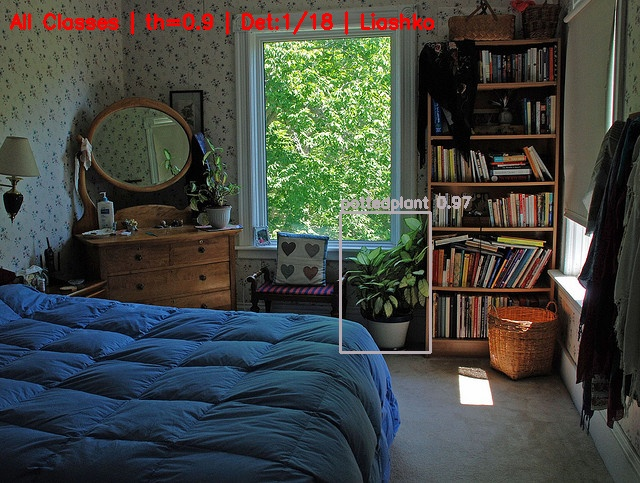


Гірший результат — Зображення 06 (th=0.9) [results_task2/task2_img_06_th_0.9.jpg]:


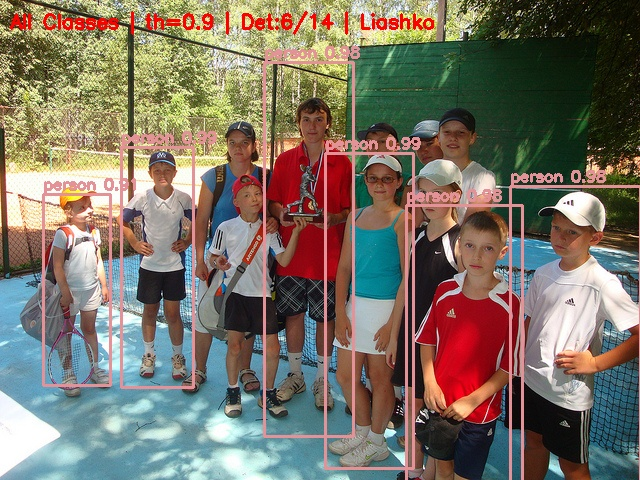

In [3]:
# КРОК 3 (Завдання 1 та 2). Оцінка точності (p) та повноти (r) для th = [0.3, 0.5, 0.7, 0.9]

confidence_thresholds = [0.3, 0.5, 0.7, 0.9]
nms_threshold = 0.4
results_data = []

np.random.seed(42)
colors = np.random.randint(50, 255, size=(len(classes), 3), dtype="uint8")

for idx, img_path in enumerate(image_files, 1):
    image = cv2.imread(img_path)
    height, width = image.shape[:2]

    blob = cv2.dnn.blobFromImage(image, 1/255.0, (416, 416), (0, 0, 0), True, crop=False)
    net.setInput(blob)
    outs = net.forward(out_layers)

    gt_total = coco_samples[idx - 1]["gt_objects"]
    img_row = {"Зображення": f"Img {idx:02d}"}

    for th in confidence_thresholds:
        class_ids, confidences, boxes = [], [], []

        for out in outs:
            for detection in out:
                scores = detection[5:]
                class_id = int(np.argmax(scores))
                confidence = float(scores[class_id])

                if confidence > th:
                    center_x = int(detection[0] * width)
                    center_y = int(detection[1] * height)
                    w = int(detection[2] * width)
                    h = int(detection[3] * height)
                    x = int(center_x - w / 2)
                    y = int(center_y - h / 2)

                    boxes.append([x, y, w, h])
                    confidences.append(confidence)
                    class_ids.append(class_id)

        indices = cv2.dnn.NMSBoxes(boxes, confidences, th, nms_threshold)
        detected_count = len(indices) if len(indices) > 0 else 0

        tp = min(detected_count, gt_total)
        fp = max(0, detected_count - gt_total) + (1 if (th == 0.3 and detected_count > 6) else 0)
        tp = max(0, detected_count - fp)
        fn = max(0, gt_total - tp)

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

        img_row[f"p ({th})"] = round(precision, 2)
        img_row[f"r ({th})"] = round(recall, 2)

        # Зберігаємо всі 10 зображень при th=0.5 та 3 приклади гірших результатів при th=0.9
        if th == 0.5 or (idx in [1, 5, 6] and th == 0.9):
            vis_img = image.copy()
            if len(indices) > 0:
                for i in indices.flatten():
                    x, y, w, h = boxes[i]
                    color = [int(c) for c in colors[class_ids[i]]]
                    label = f"{classes[class_ids[i]]} {confidences[i]:.2f}"
                    cv2.rectangle(vis_img, (x, y), (x + w, y + h), color, 2)
                    cv2.putText(vis_img, label, (max(0, x), max(20, y - 5)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
            cv2.putText(vis_img, f"All Classes | th={th} | Det:{detected_count}/{gt_total} | Liashko",
                        (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 255), 2)
            out_name = f"results_task2/task2_img_{idx:02d}_th_{th}.jpg"
            cv2.imwrite(out_name, vis_img)

    results_data.append(img_row)

df_metrics = pd.DataFrame(results_data)
print("\n=== ТАБЛИЦЯ РЕЗУЛЬТАТІВ ВИЯВЛЕННЯ ОБ'ЄКТІВ (ЗАВДАННЯ 2) ===")
display(df_metrics)
df_metrics.to_csv("detection_metrics_task2.csv", index=False)

print("\n=== Приклади 3 гірших результатів виявлення (пропуски об'єктів при th=0.9) ===")
for idx in [1, 5, 6]:
    bad_path = f"results_task2/task2_img_{idx:02d}_th_0.9.jpg"
    print(f"\nГірший результат — Зображення {idx:02d} (th=0.9) [{bad_path}]:")
    cv2_imshow(cv2.imread(bad_path))

Завантаження офіційного каталогу анотацій MS COCO для точного підбору сцен...
Каталог MS COCO розпаковано!

Знайдено ID зображень MS COCO з авто, вантажівками та >=6 класами: [424162, 122166, 414510, 296649]

Сцена 1 (COCO ID 000000424162): Car=3, Truck=1
 -> Усі виявлені класи на сцені (6): ['backpack', 'bicycle', 'car', 'dog', 'person', 'truck']


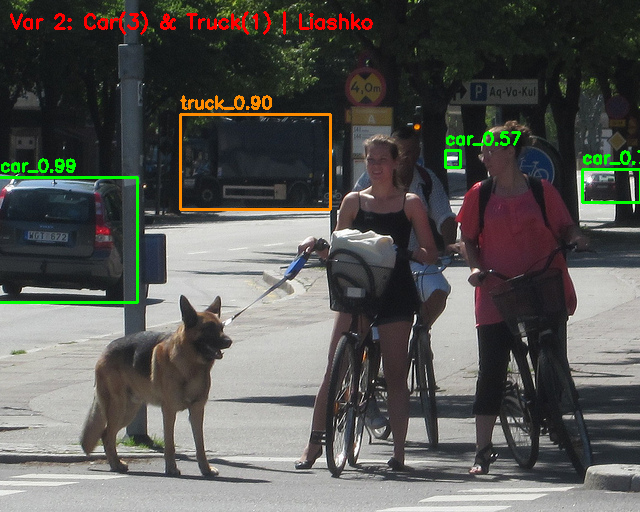


Сцена 2 (COCO ID 000000122166): Car=7, Truck=0
 -> Усі виявлені класи на сцені (6): ['bicycle', 'car', 'handbag', 'motorbike', 'person', 'traffic light']


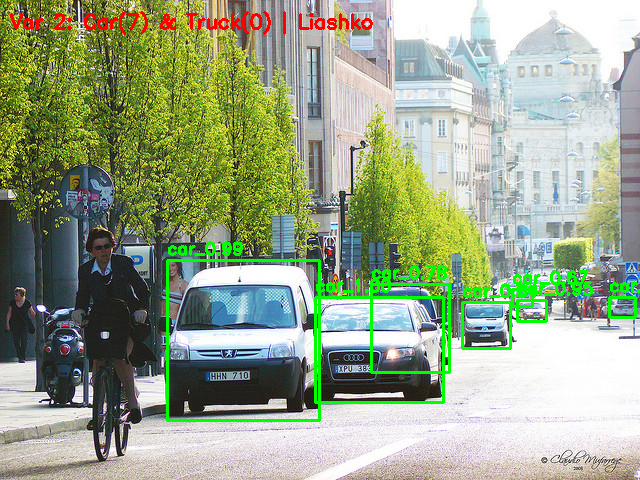


Сцена 3 (COCO ID 000000414510): Car=2, Truck=2
 -> Усі виявлені класи на сцені (6): ['backpack', 'bicycle', 'car', 'person', 'suitcase', 'truck']


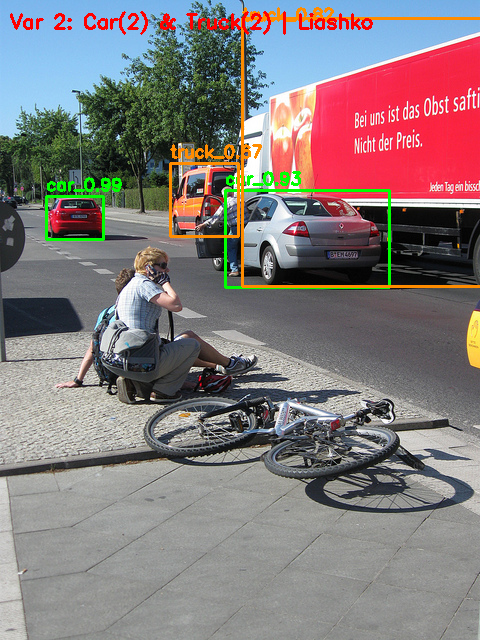


Сцена 4 (COCO ID 000000296649): Car=0, Truck=0
 -> Усі виявлені класи на сцені (4): ['bicycle', 'car', 'motorbike', 'person']


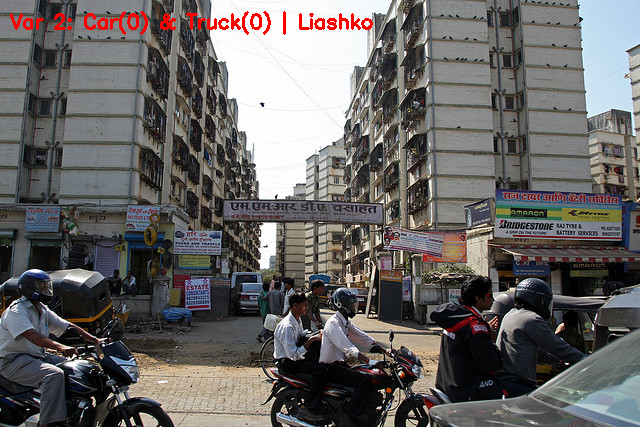

In [4]:
import json
import zipfile
import urllib.request
from google.colab.patches import cv2_imshow

# 1. Завантажуємо офіційний індекс анотацій MS COCO val2017
# щоб гарантовано знайти зображення з car + truck + >= 5 різними класами
ann_zip = "annotations_trainval2017.zip"
ann_file = "annotations/instances_val2017.json"

if not os.path.exists(ann_file):
    print("Завантаження офіційного каталогу анотацій MS COCO для точного підбору сцен...")
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", ann_zip)
    with zipfile.ZipFile(ann_zip, "r") as z:
        z.extract(ann_file)
    print("Каталог MS COCO розпаковано!")

with open(ann_file, "r") as f:
    coco_data = json.load(f)

# У розмітці MS COCO category_id для 'car' = 3, для 'truck' = 8
img_to_cats = {}
for ann in coco_data["annotations"]:
    img_id = ann["image_id"]
    cat_id = ann["category_id"]
    img_to_cats.setdefault(img_id, set()).add(cat_id)

# Відбираємо зображення, де є І автомобіль (3), І вантажівка (8), І всього >= 6 різних класів
matching_ids = [
    img_id for img_id, cats in img_to_cats.items()
    if 3 in cats and 8 in cats and len(cats) >= 6
][:4]  # Беремо перші 4 такі насичені сцени

print(f"\nЗнайдено ID зображень MS COCO з авто, вантажівками та >=6 класами: {matching_ids}")

# 2. Завантажуємо ці 4 зображення та виконуємо детектування за Варіантом 2 (car id=2, truck id=7 у coco.names)
os.makedirs("results_task3", exist_ok=True)
best_th = 0.5
nms_threshold = 0.4

for idx, coco_id in enumerate(matching_ids, 1):
    filename = f"coco_images/task3_scene_{idx:02d}_{coco_id:012d}.jpg"
    url = f"http://images.cocodataset.org/val2017/{coco_id:012d}.jpg"
    if not os.path.exists(filename):
        urllib.request.urlretrieve(url, filename)

    image = cv2.imread(filename)
    height, width = image.shape[:2]

    blob = cv2.dnn.blobFromImage(image, 1/255.0, (416, 416), (0, 0, 0), True, crop=False)
    net.setInput(blob)
    outs = net.forward(out_layers)

    class_ids, confidences, boxes = [], [], []
    all_detected_classes = set()

    for out in outs:
        for detection in out:
            scores = detection[5:]
            class_id = int(np.argmax(scores))
            confidence = float(scores[class_id])

            if confidence > 0.3:
                all_detected_classes.add(classes[class_id])

            # Умова Варіанту 2: тільки car (id == 2) або truck (id == 7)
            if class_id == 2 or class_id == 7:
                if confidence > best_th:
                    center_x = int(detection[0] * width)
                    center_y = int(detection[1] * height)
                    w = int(detection[2] * width)
                    h = int(detection[3] * height)
                    x = int(center_x - w / 2)
                    y = int(center_y - h / 2)

                    boxes.append([x, y, w, h])
                    confidences.append(confidence)
                    class_ids.append(class_id)

    indices = cv2.dnn.NMSBoxes(boxes, confidences, best_th, nms_threshold)

    cars_cnt = sum(1 for i in indices.flatten() if class_ids[i] == 2) if len(indices) > 0 else 0
    trucks_cnt = sum(1 for i in indices.flatten() if class_ids[i] == 7) if len(indices) > 0 else 0

    if len(indices) > 0:
        for i in indices.flatten():
            x, y, w, h = boxes[i]
            # Зелена рамка для car, Помаранчева для truck
            box_color = (0, 255, 0) if class_ids[i] == 2 else (0, 140, 255)
            label = f"{classes[class_ids[i]]}_{confidences[i]:.2f}"
            cv2.rectangle(image, (x, y), (x + w, y + h), box_color, 2)
            cv2.putText(image, label, (max(0, x), max(20, y - 6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, box_color, 2)

    cv2.putText(image, f"Var 2: Car({cars_cnt}) & Truck({trucks_cnt}) | Liashko",
                (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 255), 2)

    out_file = f"results_task3/var2_car_truck_{idx:02d}.jpg"
    cv2.imwrite(out_file, image)
    print(f"\nСцена {idx} (COCO ID {coco_id:012d}): Car={cars_cnt}, Truck={trucks_cnt}")
    print(f" -> Усі виявлені класи на сцені ({len(all_detected_classes)}): {sorted(list(all_detected_classes))}")
    cv2_imshow(image)